In [44]:
#task1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")
df = pd.read_csv("/content/sample_data/mpg.csv")
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [45]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    object 
 8   name          398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


In [46]:
print("Missing values:\n", df.isna().sum())
print("Duplicates:", df.duplicated().sum())

Missing values:
 mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64
Duplicates: 0


In [47]:
df["horsepower"] = df["horsepower"].fillna(df["horsepower"].median())
df = df.drop(columns=["name"])

In [48]:
df = pd.get_dummies(df, columns=["origin"], dtype=int)
print("Missing after cleaning:", df.isna().sum())
df.head()

Missing after cleaning: mpg              0
cylinders        0
displacement     0
horsepower       0
weight           0
acceleration     0
model_year       0
origin_europe    0
origin_japan     0
origin_usa       0
dtype: int64


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin_europe,origin_japan,origin_usa
0,18.0,8,307.0,130.0,3504,12.0,70,0,0,1
1,15.0,8,350.0,165.0,3693,11.5,70,0,0,1
2,18.0,8,318.0,150.0,3436,11.0,70,0,0,1
3,16.0,8,304.0,150.0,3433,12.0,70,0,0,1
4,17.0,8,302.0,140.0,3449,10.5,70,0,0,1


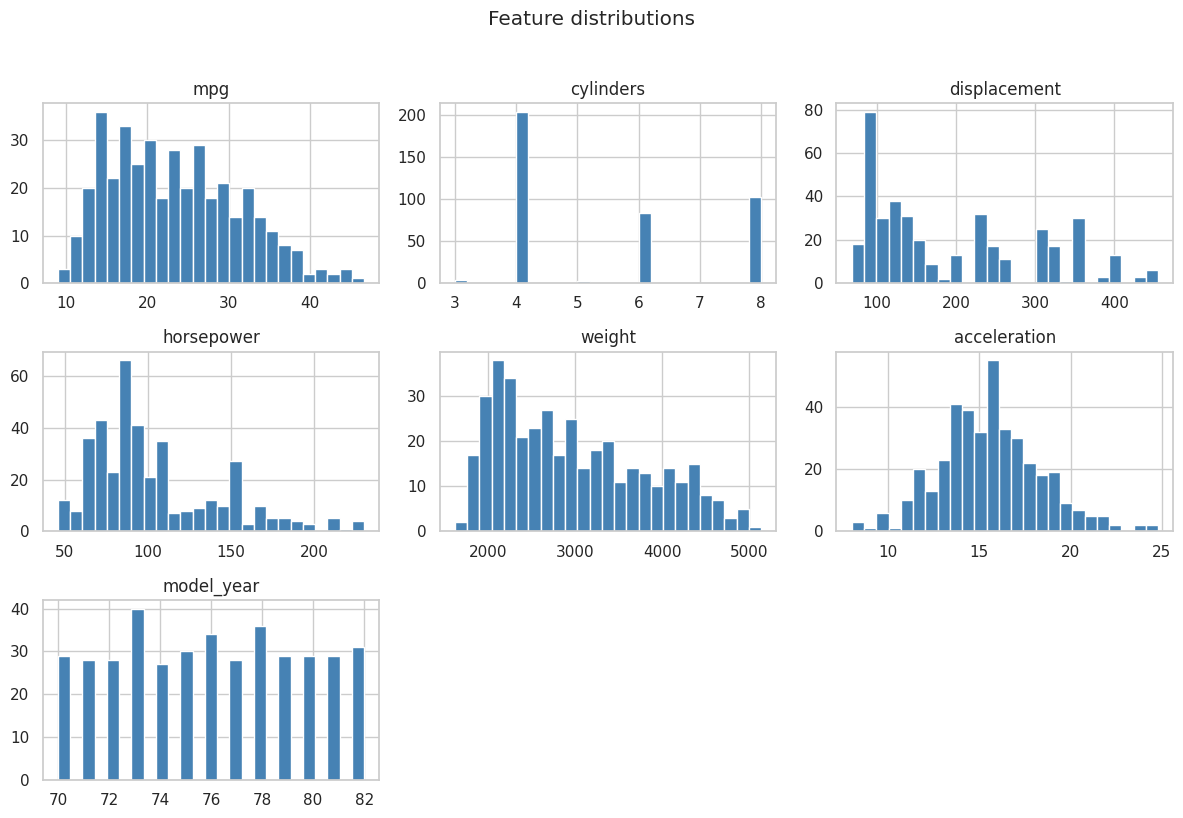

In [49]:
# Feature distributions
df.drop(columns=[c for c in df if c.startswith("origin_")]).hist(bins=25, figsize=(12, 8), color="steelblue")
plt.suptitle("Feature distributions", y=1.02)
plt.tight_layout(); plt.show()

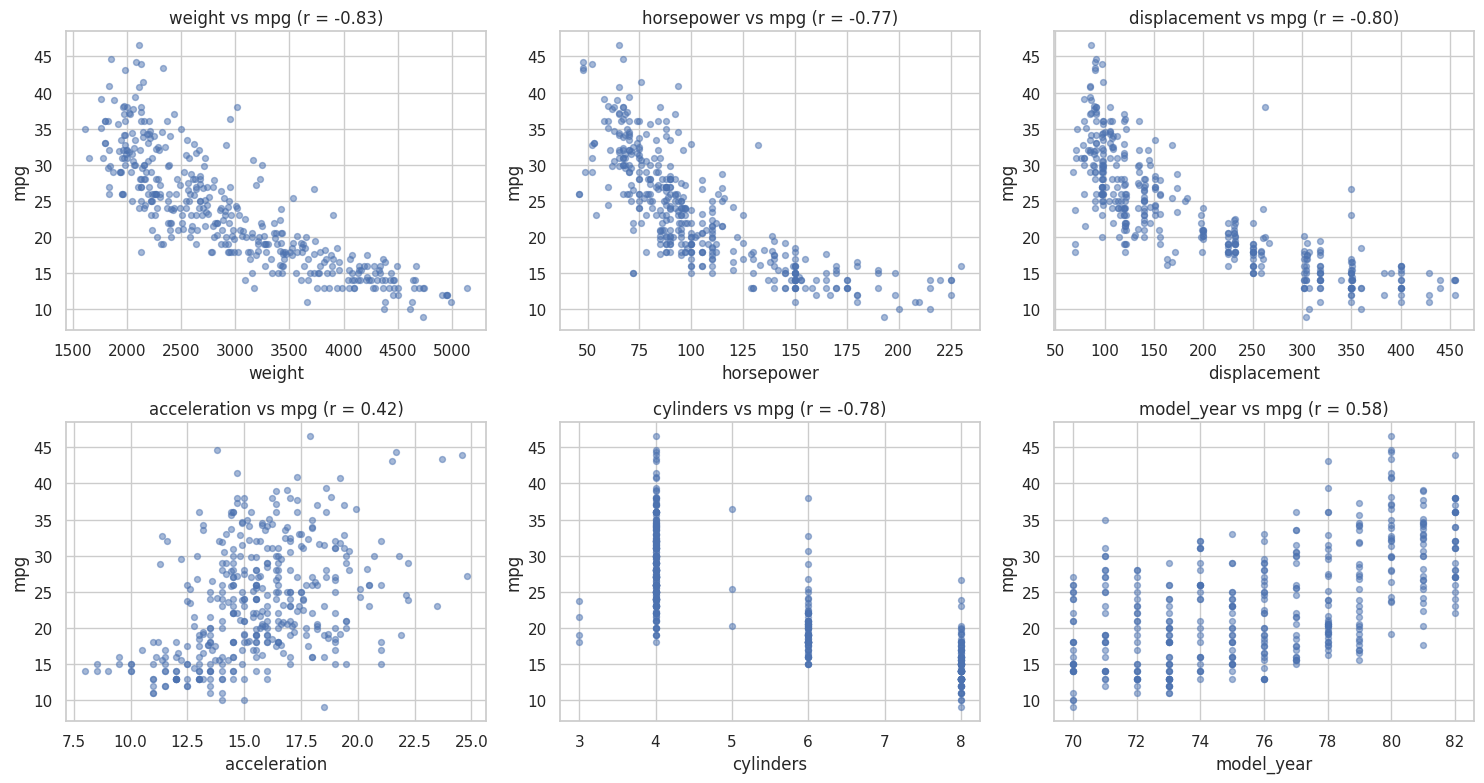

In [50]:
features = ["weight", "horsepower", "displacement", "acceleration", "cylinders", "model_year"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, f in zip(axes.ravel(), features):
    ax.scatter(df[f], df["mpg"], alpha=0.5, s=18)
    r = df[f].corr(df["mpg"])
    ax.set_title(f"{f} vs mpg (r = {r:.2f})"); ax.set_xlabel(f); ax.set_ylabel("mpg")
plt.tight_layout(); plt.show()

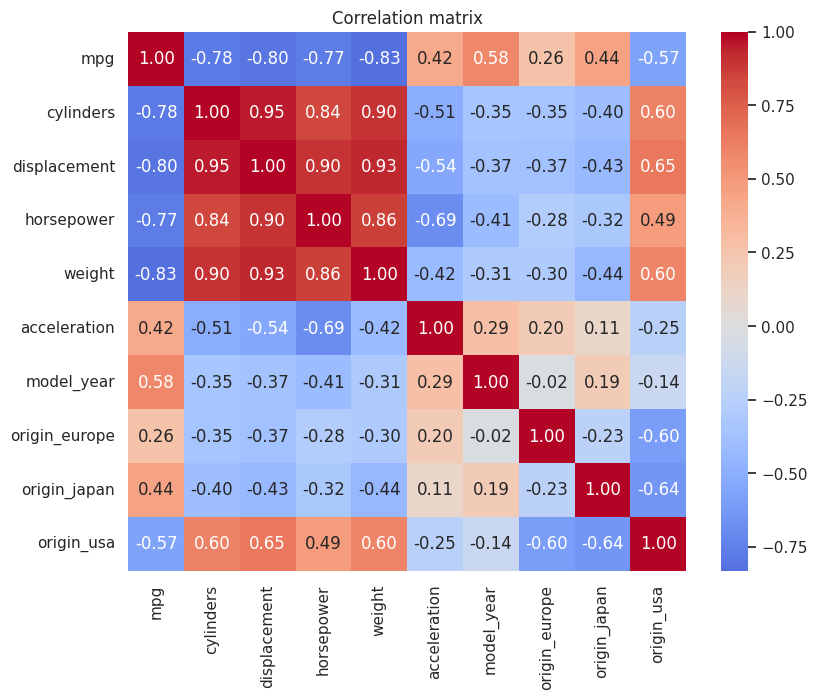

In [51]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.show()

In [52]:
X = df.drop(columns="mpg")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

multi = LinearRegression().fit(X_train, y_train)
y_pred_multi = multi.predict(X_test)

In [53]:
# Calculate evaluation metrics for the simple model
y1_pred = simple.predict(X1_test)

mse_simple = mean_squared_error(y1_test, y1_pred)
rmse_simple = np.sqrt(mse_simple)
mae_simple = mean_absolute_error(y1_test, y1_pred)

print("=== Simple Linear Regression Metrics (Weight only) ===")
print(f"MSE:  {mse_simple:.4f}")
print(f"RMSE: {rmse_simple:.4f}")
print(f"MAE:  {mae_simple:.4f}")

=== Simple Linear Regression Metrics (Weight only) ===
MSE:  14.8949
RMSE: 3.8594
MAE:  3.1178


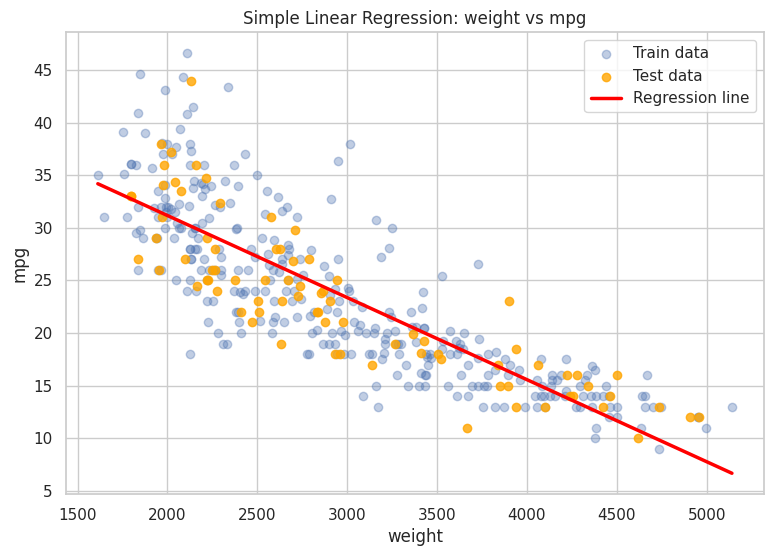

In [54]:
xs = np.linspace(X1["weight"].min(), X1["weight"].max(), 100).reshape(-1, 1)

plt.figure(figsize=(9, 6))
plt.scatter(X1_train, y_train, alpha=0.35, label="Train data")
plt.scatter(X1_test, y_test, color="orange", alpha=0.8, label="Test data")
plt.plot(xs, simple.predict(pd.DataFrame(xs, columns=["weight"])),
         color="red", lw=2.5, label="Regression line")
plt.xlabel("weight")
plt.ylabel("mpg")
plt.title("Simple Linear Regression: weight vs mpg")
plt.legend()
plt.show()